In [ ]:
# ============================================================
# BLOQUE 01 | MONTAR DRIVE Y REVISAR LOS ARCHIVOS
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os

BASE = "/content/drive/MyDrive/proyecto_datos_ia"

# Crear carpetas si no existen
for carpeta in ["modelos", "documentos", "datos/procesados", "notebooks"]:
    os.makedirs(f"{BASE}/{carpeta}", exist_ok=True)

# ARCHIVOS EN DRIVE ANTES DE SEGUIR:
#   datos/procesados/dataset_final_limpio.xlsx   -> datos de la Guía 9 (con 0)
#   datos/procesados/dataset_limpio.csv          -> dataset de la Guía 2 (con vacíos)
#   modelos/modelo_candidato_guia09.joblib       -> modelo de la Guía 9
ruta_excel = f"{BASE}/datos/procesados/dataset_final_limpio.xlsx"
ruta_csv   = f"{BASE}/datos/procesados/dataset_limpio.csv"
ruta_g9    = f"{BASE}/modelos/modelo_candidato_guia09.joblib"

print("datos/procesados/:")
print(os.listdir(f"{BASE}/datos/procesados"))
print("\nmodelos/:")
print(os.listdir(f"{BASE}/modelos"))

# Sin el Excel y el CSV no se puede seguir: si faltan se detiene
assert os.path.exists(ruta_excel), "Falta dataset_final_limpio.xlsx en datos/procesados"
assert os.path.exists(ruta_csv),   "Falta dataset_limpio.csv en datos/procesados"

print(f"\nOK Excel y CSV encontrados")
print(f"{'OK' if os.path.exists(ruta_g9) else 'WARNING '} .joblib de Guía 9: {'encontrado' if os.path.exists(ruta_g9) else 'NO encontrado (se reconstruirá en el Bloque 05)'}")

Mounted at /content/drive
datos/procesados/:
['dataset_limpio.csv', 'dataset_final_limpio.xlsx', 'predicciones_guia10.csv']

modelos/:
['modelo_candidato_guia09.joblib', 'modelo_optimizado_guia10.joblib']

OK Excel y CSV encontrados
OK .joblib de Guía 9: encontrado


In [ ]:
# ============================================================
# BLOQUE 02 | IMPORTS Y CONFIGURACIÓN GLOBAL
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, sys, time, joblib

# Herramientas Guía 10
from sklearn.pipeline import Pipeline                 # junta pasos: rellenar vacios
from sklearn.impute import SimpleImputer              # rellena vacíos con la mediana
from sklearn.ensemble import RandomForestRegressor    # el modelo a optimizar decidido guia 09
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, ParameterGrid

# Metricas y referencias de la Guia 9
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor              # baseline: siempre predice el promedio
from sklearn.base import clone                        # sacar una copia de un modelo

# semilla 42, la misma de la Guía 9.
# Pq: así los resultados salen iguales cada vez y se pueden comparar.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Estilo de los graficos
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

#
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Semilla:", RANDOM_STATE)

Python: 3.13.18
scikit-learn: 1.6.1
Semilla: 42


In [ ]:
# ============================================================
# BLOQUE 03-A | CARGA Y DIAGNOSTICO DE LOS DATOS CRUDOS
# ============================================================
df_excel = pd.read_excel(ruta_excel)
df_csv   = pd.read_csv(ruta_csv)
df_excel["event_date"] = pd.to_datetime(df_excel["event_date"])
df_csv["event_date"]   = pd.to_datetime(df_csv["event_date"])
print(f"Excel: {df_excel.shape[0]:,} filas | CSV: {df_csv.shape[0]:,} filas")

# ver el relleno de ceros vs vacíos
for col in ["avg_response_time_ms", "avg_error_rate_pct"]:
    ceros  = int((df_excel[col] == 0).sum())
    vacios = int(df_csv[col].isnull().sum())
    print(f"  {col}: el Excel tiene {ceros:,} ceros y el CSV tiene {vacios:,} vacíos")

Excel: 20,144 filas | CSV: 20,144 filas
  avg_response_time_ms: el Excel tiene 9,648 ceros y el CSV tiene 9,648 vacíos
  avg_error_rate_pct: el Excel tiene 9,648 ceros y el CSV tiene 9,648 vacíos


Dataset final: 174 filas, 12 columnas
count    174.0
mean     276.0
std       16.2
min      242.0
25%      264.0
50%      275.0
75%      287.8
max      317.0
Name: ticket_count, dtype: float64


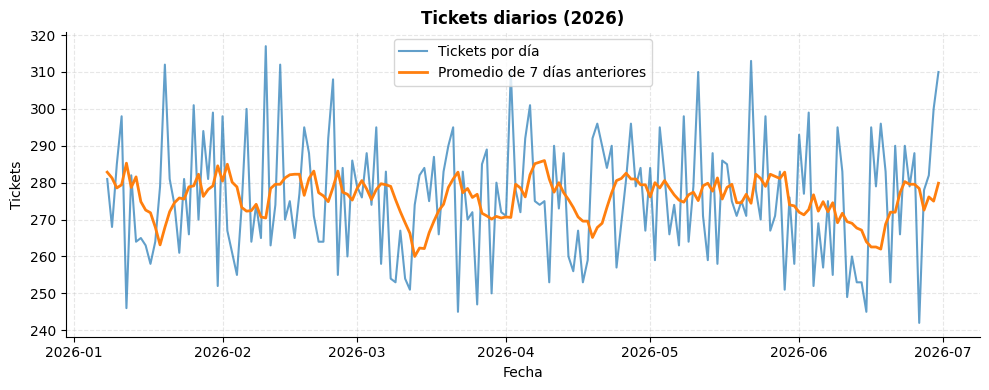

,event_date,ticket_count,deployment_count,incident_count,avg_response_time_ms,avg_error_rate_pct,dia_semana,mes,es_fin_semana,lag_1,lag_7,media_movil_7
0,2026-01-08,281,81,24,260.932576,2.473924,3,1,0,311.0,292.0,282.857143
1,2026-01-09,268,80,19,229.963127,2.097205,4,1,0,281.0,287.0,281.285714
2,2026-01-10,285,93,24,326.039755,2.735550,5,1,1,268.0,279.0,278.571429


In [ ]:
# ============================================================
# BLOQUE 03-B | CONSTRUCCION DE LA SERIE DIARIA Y VISUALIZACIÓN
# ============================================================

 # Los datos vienen por dia + empresa + area. Aqui se juntan en 1 fila por dia.
# Decision: usar el excel de la guia 9 como datos principales.
# Pq: es los mismos datos con el que se entreno el modelo de la Guia 9.


def construir_diario(df):
    """Pasa de (día x empresa x área) a una fila por día."""
    diario = (df.groupby("event_date")
                .agg(ticket_count=("ticket_count", "sum"),
                     deployment_count=("deployment_count", "sum"),
                     incident_count=("incident_count", "sum"),
                     avg_response_time_ms=("avg_response_time_ms", "mean"),
                     avg_error_rate_pct=("avg_error_rate_pct", "mean"))
                .reset_index()
                .sort_values("event_date")
                .reset_index(drop=True))

    # Variables de calendario
    diario["dia_semana"]    = diario["event_date"].dt.dayofweek        # 0 = lunes ... 6 = domingo
    diario["mes"]           = diario["event_date"].dt.month
    diario["es_fin_semana"] = diario["dia_semana"].isin([5, 6]).astype(int)

    # Variables con el pasado de los tickets
    diario["lag_1"]         = diario["ticket_count"].shift(1)          # tickets de ayer
    diario["lag_7"]         = diario["ticket_count"].shift(7)          # tickets de hace 7 dias
    diario["media_movil_7"] = diario["ticket_count"].shift(1).rolling(7).mean()   # promedio de los 7 dias anteriores
    return diario

# Limpiar los primeros 7 dias sin pasado suficiente
df_modelo = construir_diario(df_excel).dropna().reset_index(drop=True)
print(f"Dataset final: {df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas")
print(df_modelo["ticket_count"].describe().round(1))

# Grafico de la serie
fig, ax = plt.subplots()
ax.plot(df_modelo["event_date"], df_modelo["ticket_count"], label="Tickets por día", alpha=0.7)
ax.plot(df_modelo["event_date"], df_modelo["media_movil_7"], label="Promedio de 7 días anteriores", linewidth=2)
ax.set_title("Tickets diarios (2026)", fontweight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Tickets")
ax.legend()
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

df_modelo.head(3)

# AZUL ---> tickets de cada día
# NARANJA ---> promedio de los 7 días anteriores

In [ ]:
# ============================================================
# BLOQUE 04 | VARIABLES, SPLIT CRONOLÓGICO 80/20
# ============================================================
# D: mismas 10 variables de la Guía 9.
# PQ: el modelo guardado de la Guía 9 espera exactamente estas 10.

features = [
    "deployment_count", "incident_count", "avg_response_time_ms", "avg_error_rate_pct",
    "dia_semana", "mes", "es_fin_semana",
    "lag_1", "lag_7", "media_movil_7"
]
X = df_modelo[features]
y = df_modelo["ticket_count"]

# D: los primeros 80 % de los días para entrenar y el 20 % final para probar.
# Pq: en series de tiempo no se mezclan fechas; el modelo nunca ve el futuro.

corte = int(len(df_modelo) * 0.80)
X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]
fecha_test = df_modelo["event_date"].iloc[corte:]

#  si algo no cuadra, se detiene aqui
assert X_train.index.max() < X_test.index.min(), "El split no respeta el tiempo!!!!"
assert len(df_modelo) == 174, f"Se esperan! 174 días utiles y hay {len(df_modelo)}"
assert len(X_train) == 139 and len(X_test) == 35, "El split debe ser 139 / 35"

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Última fecha train: {df_modelo['event_date'].iloc[corte-1].date()}")
print(f"Primera fecha test: {df_modelo['event_date'].iloc[corte].date()}")

Train: (139, 10)  |  Test: (35, 10)
Última fecha train: 2026-05-26
Primera fecha test: 2026-05-27


In [ ]:
# ============================================================
# BLOQUE 05 | MODELO DE LA GUÍA 9 Y REFERENCIAS
# ============================================================
# comparamos el modedlo con los 2 siguientes:
#   - 9  : el Random Forest 
#   - Baseline: predecir el promedio de tickets del entrenamiento
assert os.path.exists(ruta_g9), "Falta modelo_candidato_guia09.joblib en la carpeta modelos"
modelo_guia9 = joblib.load(ruta_g9)
print("OK Modelo de Guía 9 cargado desde Drive")

# Metricas de referencia en el mismo test
pred_guia9 = modelo_guia9.predict(X_test)
mae_guia9  = mean_absolute_error(y_test, pred_guia9)
rmse_guia9 = mean_squared_error(y_test, pred_guia9) ** 0.5
r2_guia9   = r2_score(y_test, pred_guia9)

# Baseline como piso absoluto
baseline  = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred_base = baseline.predict(X_test)
mae_base  = mean_absolute_error(y_test, pred_base)
rmse_base = mean_squared_error(y_test, pred_base) ** 0.5
r2_base   = r2_score(y_test, pred_base)

print("\nReferencia:")
print(f"   Baseline → MAE: {mae_base:,.2f} | RMSE: {rmse_base:,.2f} | R²: {r2_base:.4f}")
print(f"   Guía 9   → MAE: {mae_guia9:,.2f} | RMSE: {rmse_guia9:,.2f} | R²: {r2_guia9:.4f}")

# Checar: si sale el mismo numero que en la guia09
MAE_G9_REPORTADO = 14.869      # valor del CSV de comparación de la Guia 9
print(f"\nMAE reportado por la Guia 9: {MAE_G9_REPORTADO} | recalculado: {mae_guia9:.3f}")
print("OK - coincide" if abs(mae_guia9 - MAE_G9_REPORTADO) < 0.01 else "ALERTA - no coincide")

OK Modelo de Guía 9 cargado desde Drive

Referencia:
   Baseline → MAE: 15.39 | RMSE: 18.28 | R²: -0.0215
   Guía 9   → MAE: 14.87 | RMSE: 17.63 | R²: 0.0493

MAE reportado por la Guía 9: 14.869 | recalculado: 14.869
OK - coincide


In [ ]:
# ============================================================
# BLOQUE 06 | PIPELINE
# ============================================================
# "recete del modelo a mejorar"
# El pipeline junta los pasos en orden: 1) rellenar vacios
# 2) modelo.
# D: usar pipeline con relleno por mediana (igual que la plantilla).
# Pq: en cada prueba de la busqueda, el relleno se calcula solo con los datos de
#entrenamiento de ese momento, asi no se "cuela" información de la prueba.

pipeline = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),   # rellena los vacios con la mediana
    ("modelo", RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

print(pipeline)

Pipeline(steps=[('imputador', SimpleImputer(strategy='median')),
                ('modelo', RandomForestRegressor(n_jobs=1, random_state=42))])


In [9]:
# ============================================================
# BLOQUE 07 | GRID DE HIPERPARÁMETROS ( AJUSTES A PROBAR)
# ============================================================
# Los hiperparámetros son los "ajustes" del Random Forest.
#se listan las opcione  y la busqueda prueba las combinaciones.
# El DOBLE guion bajo (modelo__) dice a pipeline que el ajuste es del paso "modelo".
# Si se escribe con un solo guion, no funciona.
#
# D usar el mismo grid de 36
# Pq: corre en segundos, y con solo 139 días de entrenamiento un grid suficiente
param_grid = {
    "modelo__n_estimators":     [100, 200],      # cuaantos árboles
    "modelo__max_depth":        [5, 10, None],   # que tan profundo puede ser cada árbol
    "modelo__min_samples_leaf": [1, 3, 5],       # minimo de dias por hoja (más alto = más simple)
    "modelo__max_features":     [0.7, 1.0]       # porcentaje de variables que ve cada árbol
}

combinaciones = list(ParameterGrid(param_grid))
print(f"Combinaciones totales: {len(combinaciones)}")
print(f"Entrenamientos esperados (combos × folds): {len(combinaciones) * 4}")



Combinaciones totales: 36
Entrenamientos esperados (combos × folds): 144


In [ ]:
# ============================================================
# BLOQUE 08 | CONFIGURAR GRIDSEARCH CV
# ============================================================
# Un fold es un pedazo de los datos de entrenamiento que se separa para evaluar.
# D: 4 folds por fechas (cada fold valida con dias POSTERIORES a los que entrena).
cv = TimeSeriesSplit(n_splits=4)

print("Folds de validación temporal (solo sobre X_train):")
for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train), 1):
    print(f"  Fold {fold}: train {idx_tr[0]}–{idx_tr[-1]}  |  val {idx_val[0]}–{idx_val[-1]}")

busqueda = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",   # MAE con signo invertido (sklearn busca el mas alto)
    cv=cv,
    n_jobs=-1,                           # usa todos los nucleos para probar combinaciones
    refit=True,                          # al final reentrena al ganador con todo X_train
    return_train_score=True,             # guarda el error de entrenamiento (para la brecha)
    error_score="raise",                 # si algo falla, que avise
    verbose=1
)

print("\nOK GridSearchCV configurado. Listo para .fit()")

Folds de validación temporal (solo sobre X_train):
  Fold 1: train 0–30  |  val 31–57
  Fold 2: train 0–57  |  val 58–84
  Fold 3: train 0–84  |  val 85–111
  Fold 4: train 0–111  |  val 112–138

OK GridSearchCV configurado. Listo para .fit()


In [ ]:
# ============================================================
# BLOQUE 09 | EJECUTAR LA BÚSQUEDA (SOLO X_TRAIN)
# ============================================================
#  se entrena SOLO con X_train / y_train.
# El 20 % final no se usa aqui para nada.
inicio = time.perf_counter()
busqueda.fit(X_train, y_train)   
tiempo_total = time.perf_counter() - inicio

print("\n" + "=" * 55)
print(f"Tiempo total: {tiempo_total:.2f} s")
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"MAE real en CV: {-busqueda.best_score_:,.2f}")
print("=" * 55)

Fitting 4 folds for each of 36 candidates, totalling 144 fits

Tiempo total: 44.62 s
Mejores parámetros: {'modelo__max_depth': 10, 'modelo__max_features': 0.7, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
MAE real en CV: 13.30


In [ ]:
# ============================================================
# BLOQUE 10 | RESULTADOS DE LA BUSQUEDA EN UNA TABLA
# ============================================================
resultados = pd.DataFrame(busqueda.cv_results_)

# Columnas de interes 
columnas = ["rank_test_score", "mean_test_score", "std_test_score",
            "mean_train_score", "mean_fit_time", "params"]
tabla_grid = resultados[columnas].copy()

# El score viene negativo se pasa a MAE normal
tabla_grid["MAE_validacion"]    = -tabla_grid["mean_test_score"]    # error en datos que no vio
tabla_grid["MAE_entrenamiento"] = -tabla_grid["mean_train_score"]   # error en los datos con que aprendio

# Brecha: si es muy grande, el modelo esta memorizando
tabla_grid["Brecha_MAE"]        = tabla_grid["MAE_validacion"] - tabla_grid["MAE_entrenamiento"]

# Ordenar: ranking 1 = la mejor combinacion
tabla_grid = tabla_grid.sort_values("rank_test_score").reset_index(drop=True)
tabla_grid.head(10).round(3)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,mean_fit_time,params,MAE_validacion,MAE_entrenamiento,Brecha_MAE
0,1,-13.300,0.745,-9.857,0.852,"{'modelo__max_depth': None, 'modelo__max_featu...",13.300,9.857,3.443
1,1,-13.300,0.745,-9.857,0.467,"{'modelo__max_depth': 10, 'modelo__max_feature...",13.300,9.857,3.443
2,3,-13.309,0.905,-9.863,0.243,"{'modelo__max_depth': 10, 'modelo__max_feature...",13.309,9.863,3.446
3,3,-13.309,0.905,-9.863,0.458,"{'modelo__max_depth': None, 'modelo__max_featu...",13.309,9.863,3.446
4,5,-13.329,0.716,-10.000,0.774,"{'modelo__max_depth': 5, 'modelo__max_features...",13.329,10.000,3.329
5,6,-13.341,0.881,-9.993,0.411,"{'modelo__max_depth': 5, 'modelo__max_features...",13.341,9.993,3.347
6,7,-13.452,0.910,-9.801,0.594,"{'modelo__max_depth': 5, 'modelo__max_features...",13.452,9.801,3.651
7,8,-13.452,0.910,-9.645,0.485,"{'modelo__max_depth': 10, 'modelo__max_feature...",13.452,9.645,3.808
8,8,-13.452,0.910,-9.645,0.461,"{'modelo__max_depth': None, 'modelo__max_featu...",13.452,9.645,3.808
9,10,-13.514,1.111,-9.755,0.246,"{'modelo__max_depth': 5, 'modelo__max_features...",13.514,9.755,3.759


In [13]:
# ============================================================
# BLOQUE 11 | TOP 10 CONFIGURACIONES Y GRAFICO
# ============================================================
top10 = tabla_grid.head(10).copy()
top10["config"] = top10["params"].apply(lambda d: dict(d))
display(top10[["rank_test_score", "MAE_validacion", "std_test_score",
               "MAE_entrenamiento", "Brecha_MAE", "mean_fit_time"]].round(2))


,rank_test_score,MAE_validacion,std_test_score,MAE_entrenamiento,Brecha_MAE,mean_fit_time
0,1,13.30,0.75,9.86,3.44,0.85
1,1,13.30,0.75,9.86,3.44,0.47
2,3,13.31,0.90,9.86,3.45,0.24
3,3,13.31,0.90,9.86,3.45,0.46
4,5,13.33,0.72,10.00,3.33,0.77
5,6,13.34,0.88,9.99,3.35,0.41
6,7,13.45,0.91,9.80,3.65,0.59
7,8,13.45,0.91,9.64,3.81,0.48
8,8,13.45,0.91,9.64,3.81,0.46
9,10,13.51,1.11,9.76,3.76,0.25


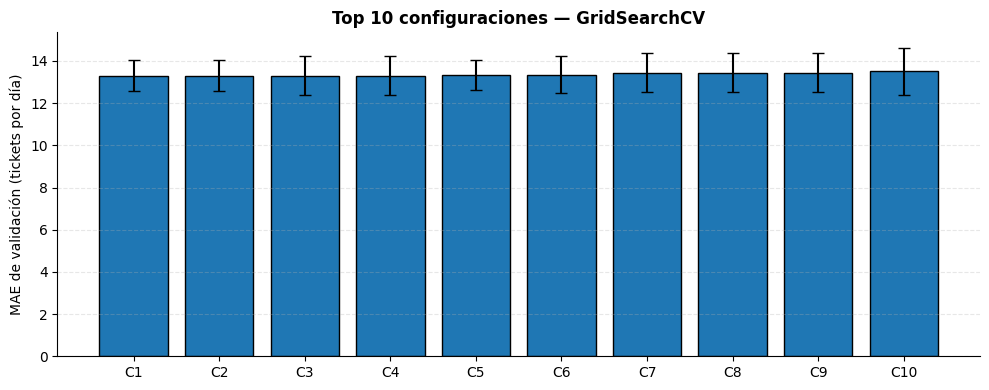

In [14]:


# Grafico del top 10 (barra = error promedio linea negra = variacion entre folds)
top = tabla_grid.nsmallest(10, "MAE_validacion").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(top)), top["MAE_validacion"],
       yerr=top["std_test_score"], capsize=4, edgecolor="black")
ax.set_xticks(range(len(top)))
ax.set_xticklabels([f"C{i+1}" for i in range(len(top))])
ax.set_ylabel("MAE de validación (tickets por día)")
ax.set_title("Top 10 configuraciones — GridSearchCV", fontweight="bold")
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# BLOQUE 12 | EVALUAR EL PIPELINE OPTIMIZADO EN EL 20 % FINAL
# ============================================================
# D: no volver a ajustar nada despues de ver este resultado.
# Pq: si se ajusta viendo la prueba el resultado deja de ser honesto.
modelo_optimizado = busqueda.best_estimator_   # ya viene entrenado con todo X_train
pred_test = modelo_optimizado.predict(X_test)  # ! -- primera y unica vez que ve el 20 % final

mae  = mean_absolute_error(y_test, pred_test)
rmse = mean_squared_error(y_test, pred_test) ** 0.5
r2   = r2_score(y_test, pred_test)

print("Modelo optimizado — Holdout final:")
print(f"   MAE:  {mae:,.2f}")
print(f"   RMSE: {rmse:,.2f}")
print(f"   R²:   {r2:.4f}")

Modelo optimizado — Holdout final:
   MAE:  14.86
   RMSE: 17.70
   R²:   0.0415


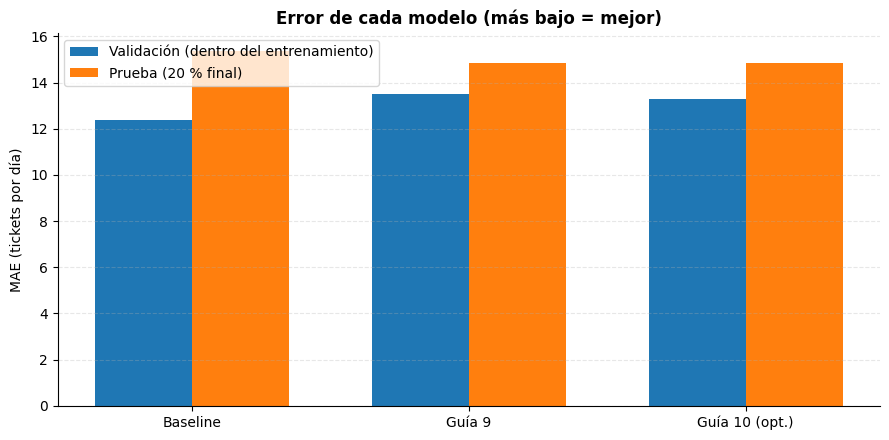

,Modelo,MAE,RMSE,R2,MAE_validacion,Mejora_vs_baseline_%,Mejora_vs_G9_%,Mejora_vs_baseline_valid_%
0,Baseline,15.39,18.28,-0.02,12.39,0.00,-3.47,0.00
1,Guía 9,14.87,17.63,0.05,13.51,3.36,0.00,-9.04
2,Guía 10 (opt.),14.86,17.70,0.04,13.30,3.40,0.04,-7.30


In [ ]:
# ============================================================
# BLOQUE 13 | COMPARACIÓN: BASELINE / g09 / g10
# ============================================================
# Ademas del 20 % final, se mide el error en validación (dentro del entrenamiento)
# para ver si el resultado se sostiene o fue suerte.
# FUNCION (mae_cv):
# Hace lo mismo que GridSearchCV hace por dentro: entrena con un pedazo de las fechas,
# prueba con las fechas siguientes, repite 4 veces y devuelve el promedio del error.
# Sirve para medir el baseline y la Guía 9 con la misma comparativa que el modelo optimizado.(guia10)
def mae_cv(estimador, X_datos, y_datos):
    """MAE promedio de los 4 folds, usando solo datos de entrenamiento."""
    maes = []
    for idx_tr, idx_val in cv.split(X_datos):
        copia = clone(estimador).fit(X_datos.iloc[idx_tr], y_datos.iloc[idx_tr])
        maes.append(mean_absolute_error(y_datos.iloc[idx_val], copia.predict(X_datos.iloc[idx_val])))
    return np.mean(maes)

cv_base  = mae_cv(DummyRegressor(strategy="mean"), X_train, y_train)
cv_guia9 = mae_cv(modelo_guia9, X_train, y_train)
cv_g10   = -busqueda.best_score_

comparacion_guia10 = pd.DataFrame([
    {"Modelo": "Baseline",       "MAE": mae_base,  "RMSE": rmse_base,  "R2": r2_base,  "MAE_validacion": cv_base},
    {"Modelo": "Guía 9",         "MAE": mae_guia9, "RMSE": rmse_guia9, "R2": r2_guia9, "MAE_validacion": cv_guia9},
    {"Modelo": "Guía 10 (opt.)", "MAE": mae,       "RMSE": rmse,       "R2": r2,       "MAE_validacion": cv_g10}
])

# % que se redujo el error (positivo = mejor; negativo = queda peor)
comparacion_guia10["Mejora_vs_baseline_%"] = (
    (mae_base - comparacion_guia10["MAE"]) / mae_base * 100
)
comparacion_guia10["Mejora_vs_G9_%"] = (
    (mae_guia9 - comparacion_guia10["MAE"]) / mae_guia9 * 100
)
comparacion_guia10["Mejora_vs_baseline_valid_%"] = (
    (cv_base - comparacion_guia10["MAE_validacion"]) / cv_base * 100
)

# Grafico: error de cada modelo (mas bajo = mejor)
posiciones = np.arange(len(comparacion_guia10))
ancho = 0.35
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(posiciones - ancho/2, comparacion_guia10["MAE_validacion"], ancho, label="Validación (dentro del entrenamiento)")
ax.bar(posiciones + ancho/2, comparacion_guia10["MAE"], ancho, label="Prueba (20 % final)")
ax.set_xticks(posiciones)
ax.set_xticklabels(comparacion_guia10["Modelo"])
ax.set_ylabel("MAE (tickets por día)")
ax.set_title("Error de cada modelo (más bajo = mejor)", fontweight="bold")
ax.legend()
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

comparacion_guia10.round(2)

In [17]:
# ============================================================
# BLOQUE 14 | TOP 10 ERRORES ABSOLUTOS DEL MODELO OPTIMIZADO
# ============================================================
errores = pd.DataFrame({
    "fecha":    fecha_test.values,
    "real":     y_test.values,
    "predicho": pred_test
})
errores["error"]     = errores["real"] - errores["predicho"]
errores["error_abs"] = errores["error"].abs()

print("Estadísticas de error:")
print(f"  Error promedio: {errores['error'].mean():,.2f}")
print(f"  Error mínimo:   {errores['error'].min():,.2f}")
print(f"  Error máximo:   {errores['error'].max():,.2f}")

errores.nlargest(10, "error_abs").round(2)

Estadísticas de error:
  Error promedio: -2.25
  Error mínimo:   -38.23
  Error máximo:   34.11


,fecha,real,predicho,error,error_abs
30,2026-06-26,242,280.23,-38.23,38.23
34,2026-06-30,310,275.89,34.11,34.11
15,2026-06-11,249,277.58,-28.58,28.58
19,2026-06-15,245,272.51,-27.51,27.51
17,2026-06-13,253,277.86,-24.86,24.86
24,2026-06-20,253,275.76,-22.76,22.76
7,2026-06-03,299,276.63,22.37,22.37
12,2026-06-08,255,276.76,-21.76,21.76
18,2026-06-14,253,274.13,-21.13,21.13
33,2026-06-29,300,279.22,20.78,20.78


In [18]:
# ============================================================
# BLOQUE 15 | GUARDAR EN DRIVE (EVIDENCIA)
# ============================================================
# D: usar los mismos nombres y carpetas de la plantilla del profe.
# Pq: es la evidencia que se entrega junto con el notebook.

# 1) Registro completo de GridSearchCV
resultados.to_csv(f"{BASE}/documentos/gridsearch_resultados_guia10.csv",
                  index=False, encoding="utf-8")

# 2) Comparacion antes/despues
comparacion_guia10.to_csv(f"{BASE}/documentos/comparacion_antes_despues_guia10.csv",
                          index=False, encoding="utf-8")

# 3) Predicciones y errores
errores.to_csv(f"{BASE}/datos/procesados/predicciones_guia10.csv",
               index=False, encoding="utf-8")

# 4) Pipeline COMPLETO (imputador + modelo)
joblib.dump(modelo_optimizado, f"{BASE}/modelos/modelo_optimizado_guia10.joblib")

print("OK Artefactos guardados en Drive")

OK Artefactos guardados en Drive


In [19]:
# ============================================================
# BLOQUE 16 | METADATA (TRAZABILIDAD)
# ============================================================
# Datos para poder repetir el experimento y saber con qué se hizo.
modelo_interno = modelo_optimizado.named_steps["modelo"]

metadata = {
    "fecha_ejecucion":      pd.Timestamp.now().isoformat(),
    "python":               sys.version.split()[0],
    "scikit_learn":         sklearn.__version__,
    "random_state":         RANDOM_STATE,
    "n_combinaciones":      len(combinaciones),
    "n_folds":              cv.get_n_splits(),
    "n_train":              len(X_train),
    "n_test":               len(X_test),
    "tiempo_busqueda_s":    round(tiempo_total, 2),
    "mejores_parametros":   str(busqueda.best_params_),
    "modelo_candidato_g9":  type(modelo_guia9).__name__,
    "modelo_optimizado":    type(modelo_interno).__name__,
    "mae_guia9":            round(mae_guia9, 2),
    "mae_optimizado":       round(mae, 2),
    "mejora_vs_g9_%":       round(comparacion_guia10["Mejora_vs_G9_%"].iloc[2], 2)
}

pd.DataFrame([metadata]).to_csv(
    f"{BASE}/documentos/metadata_guia10.csv",
    index=False, encoding="utf-8"
)

for k, v in metadata.items():
    print(f"  {k}: {v}")

  fecha_ejecucion: 2026-11-17T16:37:26.656875
  python: 3.13.18
  scikit_learn: 1.6.1
  random_state: 42
  n_combinaciones: 36
  n_folds: 4
  n_train: 139
  n_test: 35
  tiempo_busqueda_s: 44.62
  mejores_parametros: {'modelo__max_depth': 10, 'modelo__max_features': 0.7, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
  modelo_candidato_g9: RandomForestRegressor
  modelo_optimizado: RandomForestRegressor
  mae_guia9: 14.87
  mae_optimizado: 14.86
  mejora_vs_g9_%: 0.04


In [20]:
# ============================================================
# BLOQUE 17 | VERIFICACIÓN FINAL — AUDITORÍA DEL EXPERIMENTO
# ============================================================
archivos_esperados = [
    f"{BASE}/documentos/gridsearch_resultados_guia10.csv",
    f"{BASE}/documentos/comparacion_antes_despues_guia10.csv",
    f"{BASE}/documentos/metadata_guia10.csv",
    f"{BASE}/datos/procesados/predicciones_guia10.csv",
    f"{BASE}/modelos/modelo_optimizado_guia10.joblib",
]

print("Auditoría final:\n")
todo_ok = True
for ruta in archivos_esperados:
    existe = os.path.exists(ruta)
    peso = f"{os.path.getsize(ruta)/1024:.1f} KB" if existe else "—"
    icono = "OK" if existe else "FAILED"
    print(f"  {icono} {os.path.basename(ruta):<45} {peso}")
    todo_ok &= existe

# Revisiones propias de este notebook
recargado = joblib.load(f"{BASE}/modelos/modelo_optimizado_guia10.joblib")
revisiones = [
    ("El modelo guardado predice igual al recargarlo", abs(recargado.predict(X_test) - pred_test).max() < 1e-9),
    ("Entrenamiento termina antes de que empiece la prueba", X_train.index.max() < X_test.index.min()),
    ("Se probaron las 36 combinaciones", len(resultados) == 36),
    ("El MAE de la Guía 9 se reprodujo", abs(mae_guia9 - MAE_G9_REPORTADO) < 0.01),
]
print()
for texto, ok in revisiones:
    print(f"  {'OK' if ok else 'FAILED'} {texto}")
    todo_ok &= ok

print("\n" + ("GOOD!!! Todos los artefactos presentes." if todo_ok
              else "WARNING!!! Algo falló. Revisar celdas previas."))

Auditoría final:

  OK gridsearch_resultados_guia10.csv              16.0 KB
  OK comparacion_antes_despues_guia10.csv          0.5 KB
  OK metadata_guia10.csv                           0.4 KB
  OK predicciones_guia10.csv                       2.5 KB
  OK modelo_optimizado_guia10.joblib               445.7 KB

  OK El modelo guardado predice igual al recargarlo
  OK Entrenamiento termina antes de que empiece la prueba
  OK Se probaron las 36 combinaciones
  OK El MAE de la Guía 9 se reprodujo

GOOD!!! Todos los artefactos presentes.


In [21]:
# ============================================================
# BLOQUE 18 | EMPAQUETAR Y DESCARGAR
# ============================================================
import zipfile
from google.colab import files

nombre_zip = "artefactos_guia10.zip"

# Los 5 archivos de evidencia (los mismos del Bloque 15 y 16)
archivos_esperados = [
    f"{BASE}/documentos/gridsearch_resultados_guia10.csv",
    f"{BASE}/documentos/comparacion_antes_despues_guia10.csv",
    f"{BASE}/documentos/metadata_guia10.csv",
    f"{BASE}/datos/procesados/predicciones_guia10.csv",
    f"{BASE}/modelos/modelo_optimizado_guia10.joblib",
]

# Crear un archivo ZIP con todos los artefactos
with zipfile.ZipFile(nombre_zip, 'w') as zipf:
    for ruta in archivos_esperados:
        if os.path.exists(ruta):
            # arcname guarda solo el nombre del archivo sin las carpetas de Drive
            zipf.write(ruta, arcname=os.path.basename(ruta))

# Descargar el ZIP a la computadora
files.download(nombre_zip)
print("OK Descarga del paquete .zip iniciada.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

OK Descarga del paquete .zip iniciada.
